# Supplementary Figure 3 — why FFPE misses variants called in fresh-frozen

Companion to Supplementary Figure 2 panel B, which shows a large false-negative (FN) excess for the
FFPE arm. This figure attributes every one of those FNs to a reason: a SAGE filter that fired in
FFPE, a PURPLE post-filter, or — where SAGE never emitted the site at all — what the FFPE tumour
reads actually show there.

An **FN** is a variant that is `PASS` in the **FF** PURPLE somatic VCF, inside the GIAB
high-confidence regions, with FF tumour `AF ≥ 0.10`, an SNV or indel, matched on `chr:pos:ref:alt`,
and **not** in the FFPE PURPLE `PASS` set — the same definition as the Supplementary Figure 2
benchmark.

| Reason | Assigned from | Meaning |
|--------|---------------|---------|
| `sage:<FILTER>` | FFPE SAGE `FILTER` | SAGE saw the site but filtered it (`minTumorQual`, `minTumorSupport`, `minTumorVAF`, `maxEdgeDistance`, `minMQF`, …) |
| `PURPLE-dropped` | FFPE SAGE `PASS`, absent from PURPLE `PASS` | called by SAGE, removed downstream by PURPLE |
| `no_coverage` / `no_read_support` | FFPE tumour BAM | site absent from SAGE; no depth, or depth but zero alt reads |
| `reduced_alt_support_vs_FF` / `low_coverage` | FFPE tumour BAM | alt reads below the support threshold, or coverage-limited versus FF |
| `other` | FFPE tumour BAM | adequate depth and alt support, yet never called |

Each FN carries **all** the SAGE filters that fired on it, and every filter is counted separately —
so a co-occurring filter adds one to each of its slices and the slices sum to at least the FN count.
This is a prevalence view, stated on the figure.

**What this notebook reads.** Only oncoanalyser output: the two arms' PURPLE somatic VCFs, the FFPE
SAGE somatic VCF (which retains filtered records with an informative `FILTER`), and — for the sites
SAGE never emitted — the FFPE tumour `.redux.bam`. Point the Configuration cell at your run folders
and run all cells. Nothing large is downloaded: the SAGE VCF is queried through its `.tbi` at the FN
positions only, and the BAM through its `.bai` at those sites only (a few MB each, seconds of
wall-clock; the ~200 GB BAM is never scanned). Remote `gs://` input needs `gcloud auth login`,
plus `tabix` and `samtools` on `PATH`.

> The per-variant coordinates derived here are patient genomic data. They stay in memory and in the
> local cache under `data/`; the figure and every printed table are aggregate counts only.

## 1 · Configuration

In [1]:
from pathlib import Path
from collections import OrderedDict

# ============================================================================
# CONFIGURATION — edit these to point at your own oncoanalyser output.
#
# Every "folder" may be a local path or a gs:// URI, and may point at any of:
#   <run>                     the run root          (results/ is found automatically)
#   <run>/results             the results directory
#   <run>/results/<subject>   a single subject
#   <run>/<subject>/output/<subject>   older oncoanalyser layout
# Subjects and their tumour samples are auto-discovered underneath (section 4).
# ============================================================================
MODALITIES = OrderedDict([
    ("FF",   {"folder": "gs://jvt-testing/runs/oa-paper-ff-wgs",   "label": "Fresh-frozen (TN)"}),
    ("FFPE", {"folder": "gs://jvt-testing/runs/oa-paper-ffpe-ff",  "label": "FFPE (TN)"}),
])
# Where the FFPE tumour ALIGNMENTS live. The FFPE T/N calling run above reuses alignments produced
# in a separate tumour-only run, so its own alignments/ folder is absent; set this to the run that
# holds them (None = look inside the FFPE folder itself).
FFPE_ALIGNMENT_FOLDER = "gs://jvt-testing/runs/oa-paper-ffpe-wgs-to"
# GIAB high-confidence regions (GRCh38, chr-prefixed) — the FN set is restricted to these.
HIGHCONF_BED = ("gs://jvt-testing/reference_data/wigits_ref_data/3.0.0--8/38/hmftools/dna/variants/"
                "HG001_GRCh38_GIAB_highconf_CG-IllFB-IllGATKHC-Ion-10X-SOLID_CHROM1-X_v.3.3.2_"
                "highconf_nosomaticdel_noCENorHET7.bed.gz")
SUBJECT = None                 # None = the first subject present in both arms
# ============================================================================

TRUTH, TEST = list(MODALITIES)          # FF is truth, FFPE is the arm under test
VAF_MIN = 0.10                          # inclusion gate on the truth arm's tumour FORMAT AF

# Read-level thresholds for the sites SAGE never emitted (section 6). The raw depth/alt counts are
# kept, so these can be retuned without re-fetching anything.
MIN_ALT_SUPPORT = 3       # SAGE-style minimum strong alt-read support
LOW_COV_ABS     = 15      # absolute low-coverage cutoff in the FFPE tumour
COV_FRAC        = 0.5     # FFPE depth < COV_FRAC x FF depth => coverage-limited
MIN_BQ          = 10      # minimum base quality for an alt-supporting SNV read
MIN_MQ          = 1       # minimum mapping quality
RUN_TIER2       = True    # False = skip the BAM step; those FNs stay "not called by SAGE"
TIER2_WORKERS   = 6       # concurrent samtools fetches (network-bound; 1 = sequential)

TOPN = 8                  # individually coloured slices; the remainder folds into "Other"
PCT_LABEL_MIN = 0.04      # only label a slice in-place when it is this fraction or more

TUMOR_SUFFIXES  = ("T",)
NORMAL_SUFFIXES = ("R", "BL")

CACHE_ROOT = Path("data") / "supplementary_figure_3"
EXPORT_DIR = Path("figures"); EXPORT_DIR.mkdir(parents=True, exist_ok=True)
print("Truth arm:", TRUTH, MODALITIES[TRUTH]["folder"])
print("Test arm: ", TEST, MODALITIES[TEST]["folder"])
print("VAF gate:", VAF_MIN, "| Tier-2 BAM step:", "on" if RUN_TIER2 else "off")

Truth arm: FF gs://jvt-testing/runs/oa-paper-ff-wgs
Test arm:  FFPE gs://jvt-testing/runs/oa-paper-ffpe-ff
VAF gate: 0.1 | Tier-2 BAM step: on


## 2 · Locating pipeline output

Resolves the folders configured above to the directories that hold the per-tool outputs, and
provides the local / `gs://` read helpers used by the loading sections. Nothing is downloaded here.

`htslib` reads a remote `gs://` object over **https** with a bearer token (`HTS_AUTH_LOCATION`);
the `gs://` plugin fails range reads at high byte offsets, https does not. The token is written to
the cache with mode 600 and deleted again in section 6.

In [2]:
import os, subprocess, re, hashlib
from pathlib import Path

# ---- IO: identical behaviour for local paths and gs:// URIs -----------------------------------
# Every gsutil call goes through _gsutil, which returns None when the target simply does not exist
# and raises on anything else (auth, permissions, typo'd bucket). A silent [] on a failed listing
# is what makes a missing-data problem look like an empty-run problem.
_MISSING = ("matched no objects", "no urls matched", "404")

def _is_remote(p):
    return str(p).startswith("gs://")

def _gsutil(*args):
    r = subprocess.run(["gsutil", *map(str, args)], capture_output=True, text=True)
    if r.returncode != 0:
        err = r.stderr.strip()
        if any(m in err.lower() for m in _MISSING):
            return None
        raise RuntimeError(f"gsutil {' '.join(map(str, args))} failed:\n{err}")
    return r.stdout

_GLOB_CACHE = {}   # listings are memoised for the session; clear it if a run folder changes

def _glob(folder, pattern, dirs_only=True):
    # Entries matching folder/pattern, without a trailing slash. '*' never crosses a '/'.
    key = (str(folder).rstrip("/"), pattern, dirs_only)
    if key not in _GLOB_CACHE:
        _GLOB_CACHE[key] = _glob_uncached(*key)
    return _GLOB_CACHE[key]

def _glob_uncached(folder, pattern, dirs_only):
    if _is_remote(folder):
        out = _gsutil("ls", "-d", f"{str(folder).rstrip('/')}/{pattern}")
        hits = [l for l in (out or "").splitlines() if l.strip()]
        if dirs_only:
            hits = [h for h in hits if h.endswith("/")]
        return sorted(h.rstrip("/") for h in hits)
    return sorted(str(p) for p in Path(folder).glob(pattern) if p.is_dir() or not dirs_only)

def _fetch(src, dest):
    # Copy one file into the local cache. Returns None (not an exception) when the source is
    # absent, so a missing input degrades to a stated warning instead of a crash.
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    dest.parent.mkdir(parents=True, exist_ok=True)
    if _is_remote(src):
        # composite objects have no simple md5 and crcmod may be uncompiled -> skip hash checks
        if _gsutil("-o", "GSUtil:check_hashes=never", "cp", str(src), str(dest)) is None:
            return None
    else:
        if not Path(src).exists():
            return None
        import shutil; shutil.copy(Path(src), dest)
    return dest

def cache_dir(root, folder, *parts):
    """Local cache path, keyed on the source folder.

    Two runs of the same arm live in different directories, so re-pointing a folder never
    silently reuses the previous run's downloaded files.
    """
    src = str(folder).rstrip("/")
    tail = src.split("//")[-1].split("/")[-3:]                     # readable, still unambiguous
    label = re.sub(r"[^A-Za-z0-9]+", "-", "-".join(tail)).strip("-")
    return Path(root, f"{label}-{hashlib.sha1(src.encode()).hexdigest()[:6]}", *parts)

def _classify(sample):
    # Tumour vs normal from the sample-name suffix (BL checked before R: "...BL" also ends in 'L').
    for suf in NORMAL_SUFFIXES:
        if sample.endswith(suf):
            return "N"
    for suf in TUMOR_SUFFIXES:
        if sample.endswith(suf):
            return "T"
    return None

# ---- htslib transport for remote input --------------------------------------------------------
# tabix/samtools read a gs:// object over https with a bearer token; the token file is transient.
# The path must be absolute: HTS_AUTH_LOCATION is read by a child process that may have its own cwd.
HTS_TOKEN = (CACHE_ROOT / ".hts_token").resolve()

def hts_url(src):
    src = str(src)
    return "https://storage.googleapis.com/" + src[len("gs://"):] if _is_remote(src) else src

def hts_env(*srcs):
    # Environment for a tabix/samtools call. Only remote input needs (and gets) a token.
    if not any(_is_remote(s) for s in srcs):
        return dict(os.environ)
    HTS_TOKEN.parent.mkdir(parents=True, exist_ok=True)
    token = subprocess.check_output(["gcloud", "auth", "print-access-token"], text=True).strip()
    HTS_TOKEN.write_text(token)
    HTS_TOKEN.chmod(0o600)
    return dict(os.environ, HTS_AUTH_LOCATION=str(HTS_TOKEN))

# ---- Subject discovery ------------------------------------------------------------------------
# The first depth that matches anything wins. PURPLE output is the marker for a subject; the
# alignments/ folder is looked up separately because it may live in a different run.
SEARCH_DEPTHS = (
    "",             # the folder is itself a subject directory
    "*",            # the folder holds subject directories   (e.g. <run>/results)
    "results/*",    # the folder is a run root               (oncoanalyser results/ layout)
    "*/output/*",   # older layout                           (<subject>/output/<subject>)
    "*/*",          # one generic extra level
)
_PURITY_SUFFIX = ".purple.purity.tsv"

def discover_subjects(folder):
    """{subject: (tumour_sample, base)} -- one tumour per subject, read from <base>/purple/."""
    folder = str(folder).rstrip("/")
    for depth in SEARCH_DEPTHS:
        prefix = f"{depth}/" if depth else ""
        found = {}
        for hit in _glob(folder, f"{prefix}purple/*{_PURITY_SUFFIX}", dirs_only=False):
            base = hit.rsplit("/purple/", 1)[0]
            found[base.rsplit("/", 1)[-1]] = (hit.rsplit("/", 1)[-1][:-len(_PURITY_SUFFIX)], base)
        if found:
            return dict(sorted(found.items()))
    raise FileNotFoundError(
        f"No PURPLE output found under {folder}\n"
        f"  searched <folder>/{{{', '.join(d or '.' for d in SEARCH_DEPTHS)}}}/purple/*{_PURITY_SUFFIX}")

def find_redux_bam(folder, subject, sample):
    """<base>/alignments/<sample>/<sample>.redux.bam for `subject`, or None."""
    folder = str(folder).rstrip("/")
    for depth in SEARCH_DEPTHS:
        prefix = f"{depth}/" if depth else ""
        hits = _glob(folder, f"{prefix}alignments/{sample}/{sample}.redux.bam", dirs_only=False)
        hits = [h for h in hits if f"/{subject}/" in f"{h}/" or h.rsplit("/alignments/", 1)[0].endswith(subject)]
        if hits:
            return hits[0]
    return None

print("path helpers ready")

path helpers ready


## 3 · Plotting style

In [3]:
import math

import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300,
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8, "axes.titleweight": "bold",
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.8, "legend.frameon": False,
    "svg.fonttype": "none", "pdf.fonttype": 42, "ps.fonttype": 42,
})

# Categorical palette, assigned by category (not by per-pie rank) so a colour means the same
# reason in all three pies. "Other" is the neutral gray, never one of the categorical hues.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
OTHER_COLOR = "#b0afa8"
INK, MUTED = "#0b0b0b", "#52514e"

# Readable names for the non-SAGE categories; SAGE filter names are kept verbatim.
PRETTY = {
    "PURPLE-dropped": "PURPLE-dropped",
    "no_read_support": "No read support",
    "no_coverage": "No coverage",
    "reduced_alt_support_vs_FF": f"Reduced alt support vs {TRUTH}",
    "low_coverage": "Low coverage",
    "other": "Other (uncalled, adequate reads)",
    "not_called_by_sage": "Not called by SAGE (unqueried)",
}

## 4 · The false-negative set

Downloads the two PURPLE somatic VCFs (a few MB each) and the high-confidence BED, then builds

* the **truth set** — `PASS` SNVs/indels in the truth arm, inside the high-confidence regions, with
  tumour `AF ≥ VAF_MIN`, carrying the FF alt-read support and depth from `FORMAT/AD,DP` (the SAGE
  numbers PURPLE passes through — no second VCF needed for the FF baseline);
* the **test arm's `PASS` key set**, and its `FILTER` at the truth keys (for the PURPLE-dropped
  reason);
* the **FN list** = truth keys absent from the test arm's `PASS` set.

Tumour is the last sample column, normal the first (Hartwig convention).

In [4]:
import gzip
import numpy as np

SNV, INDEL = "SNV", "indel"

# ---- high-confidence BED: chrom -> (sorted starts, ends) --------------------------------------
def load_highconf(bed):
    dest = _fetch(bed, CACHE_ROOT / "highconf" / Path(str(bed)).name)
    if dest is None:
        raise FileNotFoundError(f"high-confidence BED not readable: {bed}")
    starts, ends = {}, {}
    op = gzip.open if str(dest).endswith(".gz") else open
    with op(dest, "rt") as f:
        for line in f:
            if not line.strip() or line.startswith(("track", "browser", "#")):
                continue
            ch, s, e = line.split("\t")[:3]
            starts.setdefault(ch, []).append(int(s)); ends.setdefault(ch, []).append(int(e))
    for ch in starts:
        order = np.argsort(starts[ch])
        starts[ch] = np.asarray(starts[ch])[order]; ends[ch] = np.asarray(ends[ch])[order]
    print(f"high-confidence BED: {sum(len(v) for v in starts.values()):,} intervals "
          f"over {len(starts)} contigs")
    return {"starts": starts, "ends": ends}

def in_highconf(hc, chrom, pos):
    # pos is 1-based (VCF); the BED is 0-based half-open and the variant start is the anchor.
    st = hc["starts"].get(chrom)
    if st is None:
        return False
    p0 = pos - 1
    i = int(np.searchsorted(st, p0, side="right")) - 1
    return i >= 0 and p0 < hc["ends"][chrom][i]

# ---- VCF field access (text parsing; no reference genome, no pysam) ----------------------------
def variant_kind(ref, alt):
    if len(ref) == 1 and len(alt) == 1 and ref != alt:
        return SNV
    if len(ref) != len(alt):
        return INDEL
    return None                                  # MNV / other -> not part of the benchmark

def _fmt(fmt_field, sample, key):
    # One FORMAT value for one sample column. AD returns the ALT depth (second value).
    keys = fmt_field.split(":")
    if key not in keys:
        return None
    try:
        v = sample.split(":")[keys.index(key)]
    except IndexError:
        return None
    if key == "AD":
        v = v.split(",")[1] if "," in v else None
    try:
        return float(v) if key == "AF" else int(v)
    except (TypeError, ValueError):
        return None

def somatic_vcf(modality, subject):
    tumor, base = SUBJECTS[modality][subject]
    dest = cache_dir(CACHE_ROOT, MODALITIES[modality]["folder"], subject)
    return tumor, _fetch(f"{base}/purple/{tumor}.purple.somatic.vcf.gz",
                         dest / f"{tumor}.purple.somatic.vcf.gz")

# ---- subject selection ------------------------------------------------------------------------
SUBJECTS = {m: discover_subjects(MODALITIES[m]["folder"]) for m in MODALITIES}
for m in MODALITIES:
    print(f"{m}: " + ", ".join(f"{s} ({t})" for s, (t, _) in SUBJECTS[m].items()))
shared = [s for s in SUBJECTS[TRUTH] if s in SUBJECTS[TEST]]
if not shared:
    raise FileNotFoundError(f"no subject present in both arms: {list(SUBJECTS[TRUTH])} vs {list(SUBJECTS[TEST])}")
SUBJECT = SUBJECT or shared[0]
if SUBJECT not in shared:
    raise FileNotFoundError(f"SUBJECT={SUBJECT!r} is not in both arms; shared subjects: {shared}")
print(f"\nSubject: {SUBJECT}   (shared subjects: {', '.join(shared)})")

HC = load_highconf(HIGHCONF_BED)

# ---- truth set: PASS, high-confidence, AF >= VAF_MIN ------------------------------------------
def load_truth(path):
    # {(chrom, pos, ref, alt): (kind, vaf, alt_ad, dp)}
    truth = {}
    with gzip.open(path, "rt") as f:
        for line in f:
            if line.startswith("#"):
                continue
            c = line.rstrip("\n").split("\t")
            if c[6] != "PASS":
                continue
            ref, alt = c[3], c[4].split(",")[0]
            k = variant_kind(ref, alt)
            if k is None:
                continue
            pos = int(c[1])
            if not in_highconf(HC, c[0], pos):
                continue
            vaf = _fmt(c[8], c[-1], "AF")
            if vaf is None or vaf < VAF_MIN:
                continue
            truth[(c[0], pos, ref, alt)] = (k, vaf, _fmt(c[8], c[-1], "AD"), _fmt(c[8], c[-1], "DP"))
    return truth

def load_test(path, truth):
    # (PASS key set, {truth key: FILTER}) -- the FILTER map explains the PURPLE-dropped bucket.
    passed, filt = set(), {}
    with gzip.open(path, "rt") as f:
        for line in f:
            if line.startswith("#"):
                continue
            c = line.rstrip("\n").split("\t")
            ref, alt = c[3], c[4].split(",")[0]
            if variant_kind(ref, alt) is None:
                continue
            key = (c[0], int(c[1]), ref, alt)
            if c[6] == "PASS":
                passed.add(key)
            if key in truth:
                filt[key] = c[6]
    return passed, filt

TUMOR = {}
vcfs = {}
for m in MODALITIES:
    TUMOR[m], vcfs[m] = somatic_vcf(m, SUBJECT)
    if vcfs[m] is None:
        raise FileNotFoundError(f"{m}: no {TUMOR[m]}.purple.somatic.vcf.gz for {SUBJECT}")

TRUTH_SET = load_truth(vcfs[TRUTH])
TEST_PASS, TEST_PURPLE_FILTER = load_test(vcfs[TEST], TRUTH_SET)
FN = [k for k in TRUTH_SET if k not in TEST_PASS]

n_snv = sum(1 for k in FN if TRUTH_SET[k][0] == SNV)
print(f"\n{TRUTH} PASS truth calls (high-conf, AF>={VAF_MIN}): {len(TRUTH_SET):,}")
print(f"{TEST} PURPLE PASS SNV/indel keys:                {len(TEST_PASS):,}")
print(f"FALSE NEGATIVES ({TRUTH}-only):                    {len(FN):,}"
      f"  ({100 * len(FN) / max(len(TRUTH_SET), 1):.1f}% of truth"
      f"; {n_snv:,} SNV, {len(FN) - n_snv:,} indel)")

FF: H00005238 (H00005238T), H00006429 (H00006429T)
FFPE: H00005238 (H00005238T), H00006429 (H00006429T)

Subject: H00005238   (shared subjects: H00005238, H00006429)


high-confidence BED: 438,100 intervals over 23 contigs



FF PASS truth calls (high-conf, AF>=0.1): 13,312
FFPE PURPLE PASS SNV/indel keys:                12,988
FALSE NEGATIVES (FF-only):                    3,819  (28.7% of truth; 3,501 SNV, 318 indel)


## 5 · Tier 1 — the FFPE SAGE verdict at each FN site

The test arm's SAGE somatic VCF retains every filtered record with an informative `FILTER`, so one
lookup per FN explains the bulk of them. The VCF is ~100 MB, but it is `tabix`-indexed: only the FN
positions are pulled (a few MB). If the index cannot be used the whole VCF is downloaded once into
the cache and scanned instead.

* record absent → the site goes to the BAM in section 6 (`not_called_by_sage`)
* `FILTER == PASS` → `PURPLE-dropped`
* otherwise → `sage:<FILTER>`, the stacked filter string

In [5]:
from collections import Counter

def sage_vcf_url(modality, subject):
    _, base = SUBJECTS[modality][subject]
    tumor = TUMOR[modality]
    return f"{base}/sage/somatic/{tumor}.sage.somatic.vcf.gz"

def write_site_bed(path, keys):
    # One 1-bp interval per site, in VCF order (which is coordinate-sorted).
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w") as fh:
        for chrom, pos, _, _ in keys:
            fh.write(f"{chrom}\t{pos - 1}\t{pos}\n")
    return path

def _sage_records(lines, wanted):
    # {key: (FILTER, alt_ad, dp)} for the records that match a wanted key exactly. tabix returns
    # everything overlapping the 1-bp window, so the exact-key test is what keeps this honest.
    out = {}
    for line in lines:
        if not line or line.startswith("#"):
            continue
        c = line.rstrip("\n").split("\t")
        ref, alt = c[3], c[4].split(",")[0]
        key = (c[0], int(c[1]), ref, alt)
        if key in wanted:
            out[key] = (c[6], _fmt(c[8], c[-1], "AD"), _fmt(c[8], c[-1], "DP"))
    return out

def sage_at_sites(url, keys, bed):
    """Indexed query first; fall back to downloading the whole VCF and scanning it."""
    wanted = set(keys)
    cache = cache_dir(CACHE_ROOT, MODALITIES[TEST]["folder"], SUBJECT)
    cache.mkdir(parents=True, exist_ok=True)
    try:
        # htslib caches a remote index in the working directory, so run tabix inside the cache
        # (which also means the ~1 MB .tbi is downloaded only once).
        r = subprocess.run(["tabix", "-R", str(Path(bed).resolve()), hts_url(url)],
                           env=hts_env(url), capture_output=True, text=True, cwd=cache)
        if r.returncode != 0:
            raise RuntimeError(r.stderr.strip()[:300])
        hits = _sage_records(r.stdout.splitlines(), wanted)
        print(f"tabix: {len(hits):,}/{len(wanted):,} FN sites found in {Path(url).name}")
        return hits
    except Exception as e:
        print(f"WARN: indexed query failed ({type(e).__name__}: {e}); "
              f"downloading the whole SAGE VCF once into the cache")
    dest = _fetch(url, cache / Path(url).name)
    if dest is None:
        raise FileNotFoundError(f"SAGE somatic VCF not readable: {url}")
    with gzip.open(dest, "rt") as f:
        hits = _sage_records(f, wanted)
    print(f"scan: {len(hits):,}/{len(wanted):,} FN sites found in {Path(url).name}")
    return hits

SITE_BED = write_site_bed(CACHE_ROOT / SUBJECT / "fn_sites.bed", FN)
SAGE = sage_at_sites(sage_vcf_url(TEST, SUBJECT), FN, SITE_BED)

# ---- Tier-1 reason per FN ---------------------------------------------------------------------
REASON, TIER = {}, {}
for key in FN:
    rec = SAGE.get(key)
    if rec is None:
        TIER[key], REASON[key] = "tier2_bam", "not_called_by_sage"
    elif rec[0] == "PASS":
        TIER[key] = "tier1_purple"
        REASON[key] = f"sage_PASS_dropped_by_purple(purple={TEST_PURPLE_FILTER.get(key, 'absent')})"
    else:
        TIER[key], REASON[key] = "tier1_sage", f"sage:{rec[0]}"

TIER2_SITES = [k for k in FN if TIER[k] == "tier2_bam"]
print("\n" + ", ".join(f"{t}={n:,}" for t, n in Counter(TIER.values()).most_common()))
print(f"-> {len(TIER2_SITES):,} FN never emitted by SAGE; these need the FFPE tumour BAM")

tabix: 2,863/3,819 FN sites found in H00005238T.sage.somatic.vcf.gz

tier1_sage=2,863, tier2_bam=956
-> 956 FN never emitted by SAGE; these need the FFPE tumour BAM


## 6 · Tier 2 — FFPE tumour reads at the sites SAGE never emitted

For those sites only, the FFPE tumour `.redux.bam` is read through its index: `samtools` fetches the
1-bp window around each site and each read is walked along its CIGAR to decide whether it *covers*
the anchor base and whether it *supports* the alt allele (an SNV base at `MIN_BQ`, or an
insertion/deletion of the right length immediately after the anchor). Secondary, supplementary,
duplicate, QC-fail and unmapped reads are excluded, as is `MAPQ < MIN_MQ`.

This is the one expensive step. The BAM is never scanned end to end — but on a ~200 GB WGS BAM each
indexed seek over https still transfers on the order of 10 MB, so ~1,000 sites means a few GB of
range reads: about a minute with `TIER2_WORKERS = 6`, several with one worker. Sites are split into
contiguous blocks so every worker seeks forward monotonically. Set `RUN_TIER2 = False` to skip it.

The resulting depth and alt count are turned into a category with the same rules the classifier
uses, in this order: `no_coverage` (depth 0) → `no_read_support` (no alt reads) →
`reduced_alt_support_vs_FF` (below `MIN_ALT_SUPPORT` and below FF) → `low_coverage` (below
`LOW_COV_ABS`, or below `COV_FRAC` × FF depth) → `other`.

If the BAM or its index is unavailable the step is skipped with a warning and those FNs keep the
`not_called_by_sage` label, so the figure still renders.

In [6]:
import bisect
from concurrent.futures import ThreadPoolExecutor, as_completed

_CIGAR = re.compile(r"(\d+)([MIDNSHP=X])")
_SKIP_FLAGS = 0xF04            # unmapped, secondary, QC-fail, duplicate, supplementary

def site_spec(key):
    # What "supports the alt" means at this site: a base, or an indel of a given length.
    _, _, ref, alt = key
    if len(ref) == 1 and len(alt) == 1:
        return ("SNV", 0, alt.upper())
    if len(alt) > len(ref):
        return ("INS", len(alt) - len(ref), None)
    return ("DEL", len(ref) - len(alt), None)

def eval_read(pos0, cigar, seq, qual, p0, typ, ilen, altb):
    """(covers, supports_alt) for one read at reference anchor p0 (0-based)."""
    ops = [(int(n), op) for n, op in _CIGAR.findall(cigar)]
    ref, q, n = pos0, 0, len(ops)
    for idx, (length, op) in enumerate(ops):
        if op in "M=X":                                # consume reference + query
            if ref <= p0 < ref + length:
                qi = q + (p0 - ref)
                if typ == "SNV":
                    if seq and seq != "*" and qi < len(seq):
                        bq = ord(qual[qi]) - 33 if qual and qual != "*" else 60
                        return (True, seq[qi].upper() == altb and bq >= MIN_BQ)
                    return (True, False)
                # indel: the anchor must be the last matched base and the next op the matching I/D
                if p0 == ref + length - 1 and idx + 1 < n:
                    nlen, nop = ops[idx + 1]
                    if typ == "INS" and nop == "I" and nlen == ilen:
                        return (True, True)
                    if typ == "DEL" and nop == "D" and nlen == ilen:
                        return (True, True)
                return (True, False)
            ref += length; q += length
        elif op == "D":                                # consume reference only
            if ref <= p0 < ref + length:
                return (True, False)                   # the anchor sits inside a deletion
            ref += length
        elif op == "N":                                # reference skip
            if ref <= p0 < ref + length:
                return (False, False)
            ref += length
        elif op in "IS":                               # consume query only
            q += length
        # H / P consume nothing
    return (False, False)

def tally_block(bam, bai, keys, bed, env):
    """(depth, alt) per site for one contiguous block of sites, in a single indexed pass."""
    specs = [site_spec(k) for k in keys]
    by_pos = {}
    for i, (chrom, pos, _, _) in enumerate(keys):
        by_pos.setdefault(chrom, {}).setdefault(pos - 1, []).append(i)
    sorted_pos = {chrom: sorted(d) for chrom, d in by_pos.items()}
    depth, alt = [0] * len(keys), [0] * len(keys)

    cmd = ["samtools", "view", "-F", hex(_SKIP_FLAGS), "-q", str(MIN_MQ),
           "-M", "-L", str(Path(bed).resolve()), "-X", hts_url(bam), str(Path(bai).resolve())]
    proc = subprocess.Popen(cmd, env=env, stdout=subprocess.PIPE,
                            stderr=subprocess.PIPE, text=True, bufsize=1 << 20)
    n_reads = 0
    for line in proc.stdout:
        c = line.split("\t", 11)
        chrom, pos0, cigar = c[2], int(c[3]) - 1, c[5]
        positions = sorted_pos.get(chrom)
        if positions is None or cigar == "*":
            continue
        n_reads += 1
        span = sum(int(n) for n, op in _CIGAR.findall(cigar) if op in "M=XDN")
        lo = bisect.bisect_left(positions, pos0)
        hi = bisect.bisect_right(positions, pos0 + span - 1)
        for j in range(lo, hi):
            p0 = positions[j]
            for i in by_pos[chrom][p0]:
                typ, ilen, altb = specs[i]
                covers, supports = eval_read(pos0, cigar, c[9], c[10], p0, typ, ilen, altb)
                depth[i] += covers
                alt[i] += supports
    err = proc.stderr.read()
    if proc.wait() != 0:
        raise RuntimeError(f"samtools view failed: {err.strip()[:300]}")
    return depth, alt, n_reads

def tally_sites(bam, bai, keys, workdir):
    """(depth, alt) per site. Sites are split into contiguous blocks fetched concurrently."""
    env = hts_env(bam)                      # one token for every worker; no concurrent rewrite
    n_blocks = max(1, min(TIER2_WORKERS, len(keys)))
    size = -(-len(keys) // n_blocks)
    blocks = [(i, keys[i * size:(i + 1) * size]) for i in range(n_blocks)]
    blocks = [(i, b) for i, b in blocks if b]
    depth, alt, n_reads = [0] * len(keys), [0] * len(keys), 0
    with ThreadPoolExecutor(max_workers=len(blocks)) as pool:
        futures = {}
        for i, block in blocks:
            bed = write_site_bed(workdir / f"tier2_sites.{i:02d}.bed", block)
            futures[pool.submit(tally_block, bam, bai, block, bed, env)] = (i, block)
        for done in as_completed(futures):
            i, block = futures[done]
            d, a, nr = done.result()
            depth[i * size:i * size + len(block)] = d
            alt[i * size:i * size + len(block)] = a
            n_reads += nr
            print(f"  block {i + 1}/{len(blocks)}: {len(block):,} sites, {nr:,} reads")
    print(f"read {n_reads:,} reads over {len(keys):,} site windows")
    return depth, alt

def classify_reads(depth, alt, ff_alt, ff_dp):
    if depth == 0:
        return "no_coverage"
    if alt == 0:
        return "no_read_support"
    if alt < MIN_ALT_SUPPORT and (ff_alt is None or alt < ff_alt):
        return "reduced_alt_support_vs_FF"
    if depth < LOW_COV_ABS or (ff_dp and depth < COV_FRAC * ff_dp):
        return "low_coverage"
    return "other"

BAM_DEPTH, BAM_ALT = {}, {}
if RUN_TIER2 and TIER2_SITES:
    folder = FFPE_ALIGNMENT_FOLDER or MODALITIES[TEST]["folder"]
    bam = find_redux_bam(folder, SUBJECT, TUMOR[TEST])
    bai = _fetch(f"{bam}.bai", cache_dir(CACHE_ROOT, folder, SUBJECT) / f"{TUMOR[TEST]}.redux.bam.bai") if bam else None
    if bai is None:
        print(f"WARN: no {TUMOR[TEST]}.redux.bam(+.bai) under {folder} -- skipping the read-level step;"
              f" {len(TIER2_SITES):,} FN stay 'not called by SAGE'")
    else:
        print(f"{TEST} tumour BAM: {bam}")
        try:
            d, a = tally_sites(bam, bai, TIER2_SITES, CACHE_ROOT / SUBJECT)
            for i, key in enumerate(TIER2_SITES):
                BAM_DEPTH[key], BAM_ALT[key] = d[i], a[i]
                REASON[key] = classify_reads(d[i], a[i], TRUTH_SET[key][2], TRUTH_SET[key][3])
        except Exception as e:
            print(f"WARN: read-level step failed ({type(e).__name__}: {e});"
                  f" {len(TIER2_SITES):,} FN stay 'not called by SAGE'")
elif TIER2_SITES:
    print(f"RUN_TIER2 is off -- {len(TIER2_SITES):,} FN stay 'not called by SAGE'")

HTS_TOKEN.unlink(missing_ok=True)   # the bearer token is only needed while fetching; don't keep it
if TIER2_SITES:
    print("\n" + ", ".join(f"{r}={n:,}" for r, n in
                           Counter(REASON[k] for k in TIER2_SITES).most_common()))

FFPE tumour BAM: gs://jvt-testing/runs/oa-paper-ffpe-wgs-to/H00005238/output/H00005238/alignments/H00005238T/H00005238T.redux.bam


  block 6/6: 156 sites, 14,233 reads


  block 3/6: 160 sites, 17,073 reads


  block 5/6: 160 sites, 16,571 reads


  block 4/6: 160 sites, 15,991 reads
  block 1/6: 160 sites, 16,383 reads


  block 2/6: 160 sites, 14,921 reads
read 95,172 reads over 956 site windows

no_read_support=486, reduced_alt_support_vs_FF=388, other=73, low_coverage=6, no_coverage=3


## 7 · Category counts

The aggregate table behind the figure: how often each reason fired, split SNV / indel. Because
co-occurring SAGE filters are counted individually, the column totals exceed the FN counts on the
last row.

In [7]:
def reasons_of(reason):
    # Leaf categories contributed by one FN. Stacked SAGE filters are split, so each filter
    # accumulates its own count and co-occurring filters add to every slice they belong to.
    fr = (reason or "").strip()
    if fr.startswith("sage:"):
        return [x for x in fr[len("sage:"):].split(";") if x]
    if fr.startswith("sage_PASS_dropped_by_purple"):
        return ["PURPLE-dropped"]
    return [fr] if fr else ["(unclassified)"]

def counts(keys):
    c = Counter()
    for k in keys:
        for cat in reasons_of(REASON[k]):
            c[cat] += 1
    return c

FN_SNV = [k for k in FN if TRUTH_SET[k][0] == SNV]
FN_INDEL = [k for k in FN if TRUTH_SET[k][0] == INDEL]
C_ALL, C_SNV, C_INDEL = counts(FN), counts(FN_SNV), counts(FN_INDEL)

# The TOPN most prevalent categories get their own colour and slice; the rest fold into "Other".
ORDER = [cat for cat, _ in C_ALL.most_common()]
KEEP = set(ORDER[:TOPN])
CMAP = {cat: PALETTE[i] for i, cat in enumerate(ORDER[:TOPN])}

print(f"{'category':40s} {'SNV':>7} {'indel':>7} {'total':>7}")
for cat in ORDER:
    print(f"{PRETTY.get(cat, cat):40s} {C_SNV.get(cat, 0):7d} {C_INDEL.get(cat, 0):7d} {C_ALL[cat]:7d}")
print(f"{'-- FN variants --':40s} {len(FN_SNV):7d} {len(FN_INDEL):7d} {len(FN):7d}")

category                                     SNV   indel   total
minTumorQual                                2584     195    2779
No read support                              446      40     486
Reduced alt support vs FF                    343      45     388
minTumorSupport                              352      27     379
minTumorVAF                                  130      11     141
Other (uncalled, adequate reads)              60      13      73
maxEdgeDistance                               57       5      62
minMQF                                        31      10      41
maxGermlineRelQual                            11      11      22
jitter                                         1       7       8
readStrandBias                                 0       8       8
Low coverage                                   6       0       6
fragmentStrandBias                             3       1       4
minAvgRawBaseQual                              4       0       4
No coverage              

## 8 · Figure

Three pies — all small variants, SNV only, indel only — sharing one colour map and one legend.
Identity is never colour-alone: the legend spells out every category with its count.

Wrote: figures/supplementary_figure_3.pdf figures/supplementary_figure_3.svg figures/supplementary_figure_3.png


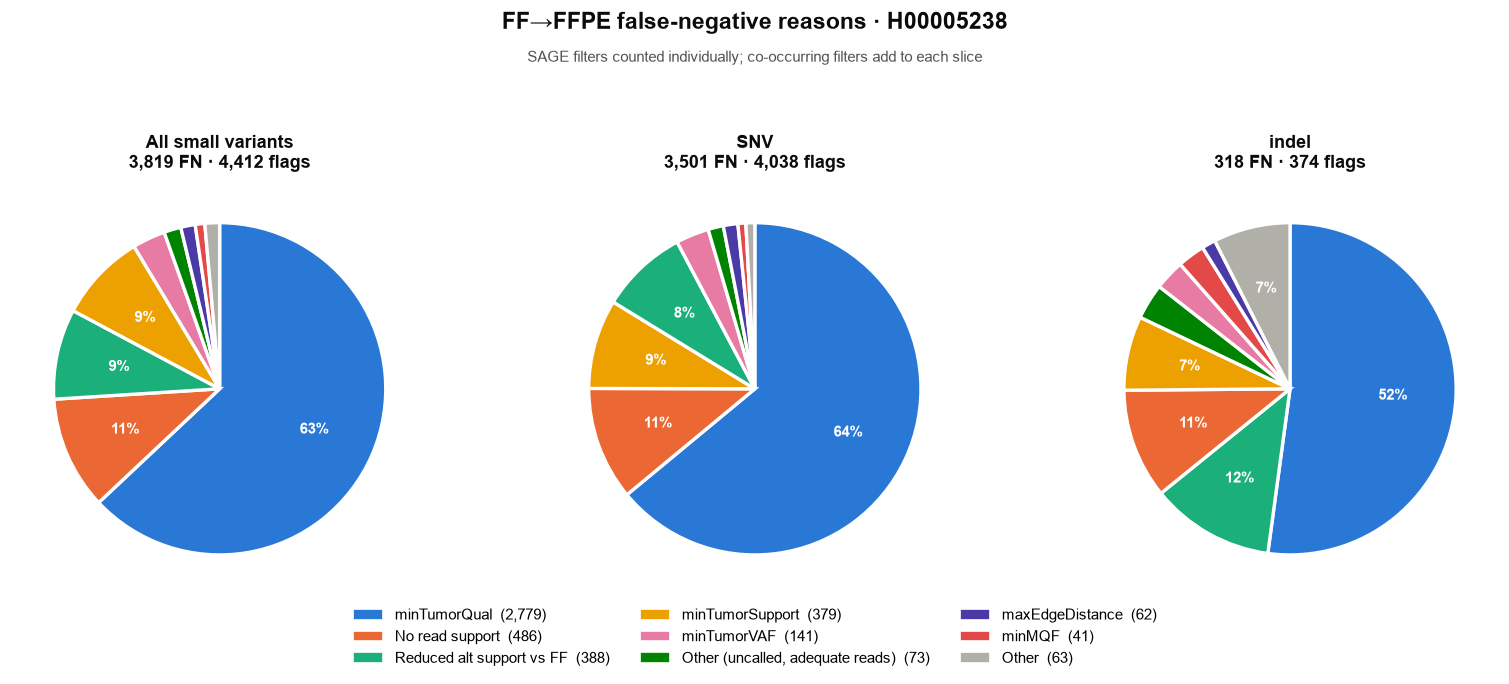

In [8]:
def collapse(c):
    # Counter -> [(label, count)] descending, with everything outside KEEP folded into "Other".
    kept = sorted(((cat, n) for cat, n in c.items() if cat in KEEP), key=lambda t: -t[1])
    other = sum(n for cat, n in c.items() if cat not in KEEP)
    return kept + ([("Other", other)] if other else [])

def draw_pie(ax, c, title, n_fn):
    data = collapse(c)
    if not data:
        ax.set_visible(False)
        return
    labels = [lab for lab, _ in data]
    vals = [n for _, n in data]
    cols = [OTHER_COLOR if lab == "Other" else CMAP.get(lab, OTHER_COLOR) for lab in labels]
    total = sum(vals)
    wedges, _ = ax.pie(vals, colors=cols, startangle=90, counterclock=False,
                       wedgeprops=dict(edgecolor="white", linewidth=2))
    # In-slice percentage, only where the wedge is wide enough to hold it.
    for w, v in zip(wedges, vals):
        frac = v / total
        if frac < PCT_LABEL_MIN:
            continue
        ang = math.radians((w.theta1 + w.theta2) / 2)
        ax.text(0.62 * math.cos(ang), 0.62 * math.sin(ang), f"{100 * frac:.0f}%",
                ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    ax.set_title(f"{title}\n{n_fn:,} FN · {total:,} flags", fontsize=11, color=INK, pad=8)

def fn_category_figure():
    fig, axes = plt.subplots(1, 3, figsize=(13.5, 5.2))
    for ax, (c, title, keys) in zip(axes, [(C_ALL, "All small variants", FN),
                                           (C_SNV, "SNV", FN_SNV),
                                           (C_INDEL, "indel", FN_INDEL)]):
        draw_pie(ax, c, title, len(keys))

    handles = [plt.Rectangle((0, 0), 1, 1, fc=CMAP[cat], ec="white") for cat in ORDER if cat in KEEP]
    labels = [f"{PRETTY.get(cat, cat)}  ({C_ALL[cat]:,})" for cat in ORDER if cat in KEEP]
    n_other = sum(n for cat, n in C_ALL.items() if cat not in KEEP)
    if n_other:
        handles.append(plt.Rectangle((0, 0), 1, 1, fc=OTHER_COLOR, ec="white"))
        labels.append(f"Other  ({n_other:,})")
    fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, fontsize=9,
               bbox_to_anchor=(0.5, -0.02))

    fig.suptitle(f"{TRUTH}→{TEST} false-negative reasons · {SUBJECT}",
                 fontsize=14, fontweight="bold", color=INK, y=1.05)
    fig.text(0.5, 0.97, "SAGE filters counted individually; co-occurring filters add to each slice",
             ha="center", fontsize=9, color=MUTED)
    fig.tight_layout(rect=[0, 0.09, 1, 0.86])
    return fig

fig = fn_category_figure()
stem = EXPORT_DIR / "supplementary_figure_3"
for ext in ("pdf", "svg", "png"):
    fig.savefig(f"{stem}.{ext}", bbox_inches="tight")
print("Wrote:", *(f"{stem}.{e}" for e in ("pdf", "svg", "png")))
plt.show()